# Predição de preço de imóveis no Rio de Janeiro
## Capítulos 1 e 2 de *O Preço da Precisão*

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vianaR25/imoveis-rio-ml/blob/main/notebooks/cap01_cap02.ipynb)

Este notebook aplica os passos dos capítulos 1 e 2 do livro *O Preço da Precisão: A Saga da Regressão* (Alvaro Riz de Barros, 2025) a uma base real: **103.301 casas e apartamentos à venda na cidade do Rio de Janeiro**, coletados nos portais QuintoAndar e Chaves na Mão em 5 e 6 de outubro de 2026.

O livro usa o *Boston Housing* como laboratório e lembra (p. 22) que o método deve ser aplicado à base da empresa, porque um modelo treinado em Boston dificilmente funcionaria no Rio. Seguimos a mesma sequência e a mesma numeração das listagens. Onde a base do Rio exige uma adaptação, o texto explica por quê.

| Capítulo | Conteúdo | Listagens |
|---|---|---|
| 1 — A Separação Sagrada dos Dados | carga, contrato de dados, divisão treino/teste e verificação | 1-1 a 1-7 |
| 2 — O Olhar do Detetive | Passo 1 inspeção, Passo 2 estatísticas, Passo 3 outliers, Passo 4 variável alvo | 2-1 a 2-8 |

## Origem e limpeza da base

Os anúncios foram coletados pelas APIs JSON que os próprios sites usam para montar as páginas de busca. O código está em `src/scraping/` e o relatório de reconhecimento dos sites em `docs/reconhecimento.md`. A limpeza é feita por `src/data/preparar.py`, antes deste notebook:

| Etapa | Imóveis |
|---|---|
| Anúncios coletados (QuintoAndar + Chaves na Mão) | 176.144 |
| Casas e apartamentos na cidade do Rio | 175.794 |
| Sem ids repetidos (a busca de apartamentos também traz as coberturas) | 165.892 |
| Sem vendas da Caixa (leilão, venda direta, licitação: o preço não é de mercado) | 161.365 |
| Com preço, área e bairro | 160.341 |
| Bairro reconhecido no município do Rio | 160.275 |
| Valores plausíveis (R\$ 50 mil a R\$ 50 mi; 15 a 5.000 m²; até 10 quartos e vagas e 12 banheiros) | 159.522 |
| Preço por m² entre R\$ 1.000 e R\$ 50.000 | 158.516 |
| **Sem anúncios repetidos do mesmo imóvel** | **103.301** |

**Repetições.** A última etapa remove 55.215 anúncios (34,8%). O mesmo imóvel é anunciado por vários corretores e nos dois portais. O caso extremo é um apartamento de 156 m² na Rua Miguel Lemos, em Copacabana, anunciado 71 vezes pelo mesmo preço. Contam como o mesmo imóvel os anúncios com a mesma área e os mesmos quartos que estejam:

- (a) no mesmo bairro e na mesma rua, com o mesmo preço ou com preço na mesma faixa de R\$ 10 mil;
- (b) na mesma rua em qualquer bairro, com o mesmo preço, porque os portais divergem no bairro das ruas de divisa;
- (c) no mesmo bairro e no mesmo portal, com coordenadas, preço e todas as características idênticos, mesmo com ruas diferentes, como as duas ruas de um prédio de esquina; ou
- (d) no mesmo bairro, com o mesmo preço e ruas de grafia parecida, como "Corrêa" e "Correia" ou "Gen. San Martin" e "General San Martin".

Um anúncio sem rua recebe a rua do par mais provável. O tipo não entra, porque o mesmo imóvel às vezes aparece como casa num anúncio e como apartamento em outro.

**Correções de valores.** A limpeza também corrige valores, sem remover linhas. Nos imóveis da base final:

- 17.077 valores de IPTU do Chaves na Mão, informados por ano, foram convertidos para mensais;
- 676 coordenadas com latitude e longitude trocadas foram desfeitas;
- 35 coordenadas fora do retângulo que envolve o município e 10 do lado errado entre as duas Freguesias foram anuladas (o Chaves na Mão usa uma coordenada padrão da Ilha do Governador também para a Freguesia de Jacarepaguá);
- 140 valores implausíveis de condomínio + IPTU foram anulados.

Quando o mesmo imóvel aparece em vários anúncios, a linha mantida herda o que falta dos outros. Assim, 19.622 imóveis do QuintoAndar, portal que não informa coordenadas, ganharam a coordenada do anúncio do mesmo imóvel no Chaves na Mão (só de anúncios do mesmo bairro), e 629 imóveis ganharam o condomínio + IPTU.

**Limpeza sem vazamento.** O capítulo 1 alerta que usar qualquer informação da base inteira antes da divisão pode vazar informação do teste (p. 21). Por isso, nenhuma etapa calcula médias ou percentis do preço. A deduplicação consulta a base inteira e compara preços entre anúncios, só para achar repetições. A padronização das grafias de bairro e a decisão entre as duas Freguesias também consultam a base inteira, sem usar o preço. Dois limites foram calibrados olhando a base completa: IPTU anual acima de R\$ 10/m² e condomínio + IPTU implausível acima de R\$ 150/m². Eles não usam o preço e só mexem em variáveis explicativas. Uma versão anterior do projeto cortava o preço por m² nos percentis 1 e 99 da base inteira. Isso usaria os preços do futuro conjunto de teste, e trocamos por limites fixos de domínio.

**Privacidade.** O arquivo público não tem link, rua, CEP nem dados do anunciante: só as 19 características usadas como variáveis, o preço, o grupo de imóvel e a data da coleta.

# Capítulo 1 — O Primeiro Mandamento: A Separação Sagrada dos Dados

Antes de qualquer análise exploratória ou transformação, a base é dividida em dois territórios isolados: o **conjunto de treino**, onde o modelo é construído, e o **conjunto de teste**, que representa o mercado desconhecido e só é usado no julgamento final (p. 20). Neste capítulo só carregamos a base, descrevemos as colunas e fazemos a divisão. Fora do treino, olhamos apenas a conferência da limpeza (Lista 1-2) e as verificações de representatividade que o próprio livro faz (Listas 1-6 e 1-7).

### Lista 1-1: Importação das bibliotecas necessárias

In [1]:
# Importando as bibliotecas necessárias
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn
from scipy import stats

# Configurando o estilo visual dos gráficos
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
AZUL, LARANJA, AQUA, CINZA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"

# Suprimindo warnings desnecessários para manter a saída limpa
import warnings
warnings.filterwarnings("ignore")

# Números no formato brasileiro (1.234.567,89)
def br(valor, casas=0):
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def reais(valor, _=None):
    """R$ abreviado para eixos e legendas: R$ 850 mil, R$ 1,2 mi."""
    return f"R$ {br(valor / 1e6, 1)} mi" if abs(valor) >= 1e6 else f"R$ {br(valor / 1e3)} mil"

print("Ambiente configurado com sucesso!")
print(f"Versão do pandas: {pd.__version__}")
print(f"Versão do numpy: {np.__version__}")
print(f"Versão do scikit-learn: {sklearn.__version__}")

Ambiente configurado com sucesso!
Versão do pandas: 2.3.1
Versão do numpy: 2.3.2
Versão do scikit-learn: 1.8.0


As versões impressas garantem a rastreabilidade: se um resultado mudar no futuro, saberemos se foi o código ou uma biblioteca (p. 23). Além do que o livro importa, carregamos o **scikit-learn**, usado na divisão, e definimos funções para escrever números no formato brasileiro.

### Lista 1-2: Carregamento do dataset

O livro lê um CSV do GitHub. Usamos o formato Parquet, que guarda os tipos das colunas e ocupa cerca de 2 MB, contra 15 MB do mesmo conteúdo em CSV. Quando o notebook roda dentro do repositório, ele lê o arquivo local; no Colab, baixa o mesmo arquivo do GitHub.

In [2]:
# Carregando o dataset: o arquivo local, se existir; senão, o publicado no GitHub (Colab)
URL = "https://raw.githubusercontent.com/vianaR25/imoveis-rio-ml/main/data/processed/imoveis_rio.parquet"
locais = [Path("data/processed/imoveis_rio.parquet"), Path("../data/processed/imoveis_rio.parquet")]
arquivo = next((p for p in locais if p.exists()), URL)
df = pd.read_parquet(arquivo)

# Visualizando as primeiras linhas
print("Primeiras 5 linhas do dataset:")
display(df.head())

# Informações básicas sobre o dataset
print(f"Dimensões do dataset: {df.shape}")
print(f"Número de amostras: {br(df.shape[0])}")
print(f"Número de features: {df.shape[1] - 3}  # sem o alvo (preco), o grupo e a data da coleta")
print(f"Data da coleta: {df['data_coleta'].min()} a {df['data_coleta'].max()}")

Primeiras 5 linhas do dataset:


,tipo,subtipo,bairro,regiao,fonte,area_m2,quartos,banheiros,suites,vagas,...,longitude,lancamento,tem_piscina,tem_churrasqueira,tem_academia,tem_varanda,sem_itens,preco,grupo,data_coleta
0,apartamento,apartamento,Irajá,Zona Norte,quintoandar,40.0,1.0,1.0,0.0,1.0,...,-43.328243,0,0,0,0,0,0,125000.0,0,2026-10-05
1,apartamento,apartamento,São Francisco Xavier,Zona Norte,quintoandar,55.0,2.0,1.0,0.0,0.0,...,NaN,0,0,0,0,0,0,140000.0,1,2026-10-05
2,apartamento,apartamento,Vaz Lobo,Zona Norte,quintoandar,49.0,2.0,1.0,0.0,0.0,...,NaN,0,0,0,0,1,0,138000.0,2,2026-10-05
3,apartamento,apartamento,Madureira,Zona Norte,quintoandar,56.0,2.0,1.0,0.0,0.0,...,NaN,0,1,1,0,1,0,130000.0,3,2026-10-05
4,apartamento,apartamento,Água Santa,Zona Norte,quintoandar,44.0,2.0,1.0,0.0,0.0,...,-43.314577,0,0,1,0,0,0,135000.0,4,2026-10-05


Dimensões do dataset: (103301, 22)
Número de amostras: 103.301
Número de features: 19  # sem o alvo (preco), o grupo e a data da coleta
Data da coleta: 2026-10-05 a 2026-10-06


A "auditoria de recebimento" (p. 24): **103.301 amostras e 22 colunas**. Delas, 19 são características do imóvel (as *features*), `preco` é a variável alvo, `grupo` identifica anúncios que podem ser o mesmo imóvel e `data_coleta` é a data em que o anúncio foi lido.

### Lista 1-2 (complemento): conferindo a limpeza

In [3]:
# Conferindo a limpeza: nenhum anúncio pode aparecer duas vezes
colunas = [c for c in df.columns if c not in ("grupo", "data_coleta")]
identicas = df.duplicated(subset=colunas, keep=False)
print(f"Linhas idênticas em todas as colunas: {identicas.sum()}")
if identicas.any():
    mesmo_grupo = df[identicas].groupby(colunas, dropna=False)["grupo"].nunique().eq(1).all()
    print(f"  cada uma no mesmo grupo das suas iguais: {mesmo_grupo}")
    print(f"  fonte: {df.loc[identicas, 'fonte'].value_counts().to_dict()}, sem coordenada: {df.loc[identicas, 'latitude'].isna().sum()}")

tamanho = df.groupby("grupo").size()
print(f"Grupos de imóvel: {br(len(tamanho))}")
print(f"Anúncios sozinhos no grupo: {br((tamanho == 1).sum())}")
print(f"Anúncios em grupos com mais de um: {br(tamanho[tamanho > 1].sum())} (maior grupo: {tamanho.max()})")

Linhas idênticas em todas as colunas: 12
  cada uma no mesmo grupo das suas iguais: True
  fonte: {'quintoandar': 12}, sem coordenada: 12
Grupos de imóvel: 77.557
Anúncios sozinhos no grupo: 67.409
Anúncios em grupos com mais de um: 35.892 (maior grupo: 678)


Restam 12 linhas idênticas em todas as colunas, formando 6 pares. São todas do QuintoAndar, sem coordenada, e as duas linhas de cada par estão em ruas diferentes. Pode ser o mesmo imóvel num prédio de esquina ou duas unidades padronizadas de um mesmo empreendimento. Sem a coordenada não há como decidir, então os pares ficam. Cada par está no mesmo grupo, e por isso nunca fica dividido entre treino e teste.

Os 35.892 anúncios em grupos com mais de um **não são necessariamente** repetições. O grupo usa um critério largo, que junta imóveis muito parecidos e também as quase duplicatas que escaparam da deduplicação (veja a Lista 1-5). O maior grupo, por exemplo, liga em cadeia 678 imóveis de 2 quartos em 22 bairros, quase todos da região de Barra e Jacarepaguá e da Zona Oeste.

> **PARA SABER: tipos de variáveis da base** (p. 24-25)
>
> | Categoria | Variáveis |
> |---|---|
> | Quantitativas contínuas | `area_m2`, `condominio_iptu`, `latitude`, `longitude` e o alvo `preco` |
> | Quantitativas discretas | `quartos`, `banheiros`, `suites`, `vagas` |
> | Qualitativas nominais | `tipo`, `subtipo`, `bairro`, `regiao`, `fonte` |
> | Qualitativas ordinais | nenhuma |
> | Binárias | `lancamento`, `tem_piscina`, `tem_churrasqueira`, `tem_academia`, `tem_varanda`, `sem_itens` |

**Tabela 1-1: Descrição das variáveis da base do Rio**

| Variável | Descrição |
|---|---|
| tipo | Tipo do imóvel: apartamento ou casa |
| subtipo | apartamento, cobertura, kitnet, casa ou casa_condominio |
| bairro | Bairro, com o nome oficial da Prefeitura |
| regiao | Região da cidade: Centro, Zona Sul, Grande Tijuca, Zona Norte, Barra e Jacarepaguá ou Zona Oeste |
| fonte | Portal de origem do anúncio |
| area_m2 | Área do imóvel em m² |
| quartos, banheiros, suites, vagas | Contagens informadas no anúncio |
| condominio_iptu | Condomínio + IPTU mensal, em R\$ |
| latitude, longitude | Coordenadas do anúncio no Chaves na Mão. O QuintoAndar não informa; seus imóveis só têm coordenada quando também estão no Chaves na Mão |
| lancamento | 1 se o anúncio é de lançamento |
| tem_piscina, tem_churrasqueira, tem_academia, tem_varanda | 1 se o anúncio lista o item |
| sem_itens | 1 se o anúncio não traz lista de itens (as comodidades valem 0 por falta de informação) |
| preco | Preço pedido de venda, em R\$ (**VARIÁVEL ALVO**) |
| grupo | Grupo de imóvel, usado só na divisão treino/teste |
| data_coleta | Data da coleta |

Como no livro, a Lista 1-3 guarda essas descrições num dicionário para consulta rápida durante a análise.

### Lista 1-3: Dicionário de descrição das features

In [4]:
# Dicionário de descrição das features
feature_descriptions = {
    "tipo": "Tipo do imóvel: apartamento ou casa",
    "subtipo": "Subtipo: apartamento, cobertura, kitnet, casa ou casa_condominio",
    "bairro": "Bairro, com o nome oficial da Prefeitura",
    "regiao": "Região da cidade (Centro, Zona Sul, Grande Tijuca, Zona Norte, Barra e Jacarepaguá, Zona Oeste)",
    "fonte": "Portal de origem do anúncio: quintoandar ou chavesnamao",
    "area_m2": "Área do imóvel em m²",
    "quartos": "Número de quartos",
    "banheiros": "Número de banheiros",
    "suites": "Número de suítes",
    "vagas": "Número de vagas de garagem",
    "condominio_iptu": "Condomínio + IPTU mensal, em R$",
    "latitude": "Latitude (do Chaves na Mão; no QuintoAndar, só quando o imóvel também está no Chaves na Mão)",
    "longitude": "Longitude (mesma origem da latitude)",
    "lancamento": "1 se o anúncio é de lançamento",
    "tem_piscina": "1 se o anúncio lista piscina",
    "tem_churrasqueira": "1 se o anúncio lista churrasqueira",
    "tem_academia": "1 se o anúncio lista academia",
    "tem_varanda": "1 se o anúncio lista varanda ou sacada",
    "sem_itens": "1 se o anúncio não traz lista de itens (as comodidades valem 0 por falta de informação)",
    "preco": "Preço pedido de venda, em R$ (VARIÁVEL ALVO)",
    "grupo": "Grupo de imóvel: anúncios que podem ser o mesmo imóvel (usado só na divisão)",
    "data_coleta": "Data em que o anúncio foi coletado",
}

print("Descrição das Features:")
for feature, description in feature_descriptions.items():
    print(f"  {feature:18s}: {description}")

Descrição das Features:
  tipo              : Tipo do imóvel: apartamento ou casa
  subtipo           : Subtipo: apartamento, cobertura, kitnet, casa ou casa_condominio
  bairro            : Bairro, com o nome oficial da Prefeitura
  regiao            : Região da cidade (Centro, Zona Sul, Grande Tijuca, Zona Norte, Barra e Jacarepaguá, Zona Oeste)
  fonte             : Portal de origem do anúncio: quintoandar ou chavesnamao
  area_m2           : Área do imóvel em m²
  quartos           : Número de quartos
  banheiros         : Número de banheiros
  suites            : Número de suítes
  vagas             : Número de vagas de garagem
  condominio_iptu   : Condomínio + IPTU mensal, em R$
  latitude          : Latitude (do Chaves na Mão; no QuintoAndar, só quando o imóvel também está no Chaves na Mão)
  longitude         : Longitude (mesma origem da latitude)
  lancamento        : 1 se o anúncio é de lançamento
  tem_piscina       : 1 se o anúncio lista piscina
  tem_churrasqueira : 1 se 

### Lista 1-4: Separando as features (X) e a variável alvo (y)

In [5]:
# Separando as features (X) da variável alvo (y)
from sklearn.model_selection import StratifiedGroupKFold

COLUNAS_FORA = ["preco", "grupo", "data_coleta"]  # alvo, grupo de imóvel e data
X = df.drop(columns=COLUNAS_FORA)
y = df["preco"]
grupos = df["grupo"]

print("Estrutura dos dados:")
print(f"X (features): {X.shape}")
print(f"y (alvo): {y.shape}")

Estrutura dos dados:
X (features): (103301, 19)
y (alvo): (103301,)


Com **X** e **y** definidos, fica estabelecido o **contrato de dados** (p. 27). Três colunas ficam fora de X:

- `preco` é o alvo;
- `grupo` serve só para a divisão: o modelo não pode aprender com ele;
- `data_coleta` é um metadado: os anúncios foram lidos em dois dias seguidos.

O preço por m² também não está em X, nem no arquivo. Ele é calculado a partir do preço, então usá-lo como variável seria entregar a resposta ao modelo.

### Lista 1-5: Separando treino e teste, 80% dos dados para treino e 20% para teste

O livro usa `train_test_split(test_size=0.2, random_state=42)`, uma divisão aleatória linha a linha. Na base do Rio essa divisão vazaria informação. Mesmo depois da limpeza, sobram anúncios quase iguais que o critério de repetição não junta. Um exemplo são dois anúncios na Rua Japurá, na Praça Seca, de 105 m² e 3 quartos: R\$ 165 mil num portal e R\$ 170 mil no outro. A deduplicação junta preços na mesma faixa de R\$ 10 mil, e esses dois caem em faixas vizinhas. Numa divisão aleatória, um anúncio ficaria no treino e o outro no teste, e o modelo seria avaliado num imóvel que já viu. É o vazamento que o capítulo 1 descreve, e ele inflaria a performance.

Por isso, a divisão é **agrupada**: todos os anúncios de um mesmo `grupo` ficam do mesmo lado. O par da Rua Japurá, por exemplo, está no mesmo grupo. Ela também é **estratificada por região**, para que as seis regiões apareçam nas duas partes na mesma proporção (a divisão estratificada do PARA SABER da p. 30). O `StratifiedGroupKFold` faz as duas coisas: separa a base em 5 partes, e a primeira vira o teste (20%). A semente é a mesma do livro, 42.

In [6]:
# A divisão estratégica: 80% para treino, 20% para teste.
# Agrupada: anúncios do mesmo grupo de imóvel ficam do mesmo lado.
# Estratificada por região: todas as regiões aparecem nos dois lados.
# random_state garante reprodutibilidade - essencial para ciência reprodutível
SEED = 42
regiao = df["regiao"].fillna("Desconhecida")
estrato = regiao.where(regiao.map(regiao.value_counts()) >= 10, "Outras")
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)  # 1 de 5 partes = 20% para teste
i_treino, i_teste = next(divisor.split(X, estrato, groups=grupos))

X_train, X_test = X.iloc[i_treino], X.iloc[i_teste]
y_train, y_test = y.iloc[i_treino], y.iloc[i_teste]

# Verificando as dimensões dos conjuntos resultantes
print("=" * 60)
print("DIVISÃO DOS DADOS CONCLUÍDA")
print("=" * 60)
print("Conjunto de TREINO:")
print(f"  X_train: {br(X_train.shape[0])} amostras, {X_train.shape[1]} features")
print(f"  y_train: {br(y_train.shape[0])} valores alvo")
print("\nConjunto de TESTE (SELADO):")
print(f"  X_test:  {br(X_test.shape[0])} amostras, {X_test.shape[1]} features")
print(f"  y_test:  {br(y_test.shape[0])} valores alvo")
print(f"\nProporção do teste: {len(i_teste) / len(df):.1%}")
print(f"Grupos de imóvel nos dois lados: {len(set(grupos.iloc[i_treino]) & set(grupos.iloc[i_teste]))}")
print(f"Impressão digital do teste: {hashlib.md5(np.sort(i_teste).tobytes()).hexdigest()[:10]}")
print("=" * 60)

DIVISÃO DOS DADOS CONCLUÍDA
Conjunto de TREINO:
  X_train: 82.641 amostras, 19 features
  y_train: 82.641 valores alvo

Conjunto de TESTE (SELADO):
  X_test:  20.660 amostras, 19 features
  y_test:  20.660 valores alvo

Proporção do teste: 20.0%
Grupos de imóvel nos dois lados: 0
Impressão digital do teste: c7792353de


**82.641 imóveis de treino e 20.660 de teste**, exatamente 20%, sem nenhum grupo dos dois lados. A *impressão digital* é um resumo dos índices do teste: os notebooks dos próximos capítulos refazem a divisão e conferem que o teste é o mesmo.

### Lista 1-6: Verificando se a divisão preservou a distribuição da variável alvo

In [7]:
# Verificando se a divisão preservou a distribuição da variável alvo
def estatisticas(serie):
    return pd.Series({"Média": serie.mean(), "Mediana": serie.median(), "Desvio": serie.std(),
                      "Mínimo": serie.min(), "Máximo": serie.max()})

print("Verificação da Representatividade da Divisão:")
print("-" * 60)
print("Estatísticas da variável alvo (preco), em R$ mil:")
tabela = pd.DataFrame({"Completo": estatisticas(y), "Treino": estatisticas(y_train),
                       "Teste": estatisticas(y_test)}) / 1000
display(tabela.style.format(lambda v: br(v, 1)))

# Divisão por bins: a proporção de imóveis em cada faixa de preço
faixas = [0, 300e3, 600e3, 1e6, 2e6, 5e6, np.inf]
nomes = ["até 300 mil", "300 a 600 mil", "600 mil a 1 mi", "1 a 2 mi", "2 a 5 mi", "acima de 5 mi"]
def proporcao(serie):
    return pd.cut(serie, faixas, labels=nomes).value_counts(normalize=True, sort=False) * 100

print("Imóveis por faixa de preço (%):")
display(pd.DataFrame({"Completo": proporcao(y), "Treino": proporcao(y_train),
                      "Teste": proporcao(y_test)}).style.format(lambda v: br(v, 1)))

print("Imóveis por região (%), a variável usada na estratificação:")
display(pd.DataFrame({"Completo": regiao.value_counts(normalize=True) * 100,
                      "Treino": regiao.iloc[i_treino].value_counts(normalize=True) * 100,
                      "Teste": regiao.iloc[i_teste].value_counts(normalize=True) * 100}).style.format(lambda v: br(v, 1)))

Verificação da Representatividade da Divisão:
------------------------------------------------------------
Estatísticas da variável alvo (preco), em R$ mil:


,Completo,Treino,Teste
Média,"1.490,1","1.488,9","1.495,0"
Mediana,"820,0","820,0","800,0"
Desvio,"2.137,8","2.116,4","2.221,0"
Mínimo,"50,0","50,0","56,0"
Máximo,"42.257,9","42.257,9","38.000,0"


Imóveis por faixa de preço (%):


,Completo,Treino,Teste
preco,,,
até 300 mil,"16,3","16,0","17,7"
300 a 600 mil,"22,2","22,3","21,8"
600 mil a 1 mi,"20,1","20,2","19,8"
1 a 2 mi,"21,9","22,0","21,5"
2 a 5 mi,"14,9","15,0","14,6"
acima de 5 mi,"4,6","4,6","4,7"


Imóveis por região (%), a variável usada na estratificação:


,Completo,Treino,Teste
regiao,,,
Barra e Jacarepaguá,"38,5","38,5","38,5"
Zona Sul,"24,8","24,8","24,8"
Zona Norte,"18,0","18,0","18,0"
Grande Tijuca,"10,6","10,6","10,6"
Zona Oeste,"4,4","4,4","4,4"
Centro,"3,7","3,7","3,7"


As médias ficam em R\$ 1,489 mi no treino e R\$ 1,495 mi no teste, e as medianas em R\$ 820 mil e R\$ 800 mil. O desvio do teste é um pouco maior (R\$ 2,22 mi contra R\$ 2,12 mi). O máximo difere (R\$ 42,3 mi no treino, R\$ 38,0 mi no teste), o que é natural: um único imóvel define o máximo de cada lado.

A tabela de faixas aplica a ideia de **divisão por bins** do livro (p. 30). Na maioria das faixas, a proporção difere no máximo 0,5 ponto percentual entre treino e teste. A maior diferença, de 1,7 ponto, está nos imóveis até R\$ 300 mil (17,7% no teste e 16,0% no treino). Como a divisão mantém grupos inteiros, e alguns grupos têm centenas de anúncios, as proporções não ficam idênticas. As regiões têm praticamente a mesma proporção, iguais até a primeira casa decimal, porque foram a variável da estratificação.

### Lista 1-7: Visualização da distribuição da variável alvo nos três conjuntos

O preço vai de R\$ 50 mil a R\$ 42 milhões. Na escala natural, quase todos os imóveis ficariam espremidos numa única barra, então o eixo horizontal usa escala logarítmica. A distribuição na escala natural é analisada no Passo 4.

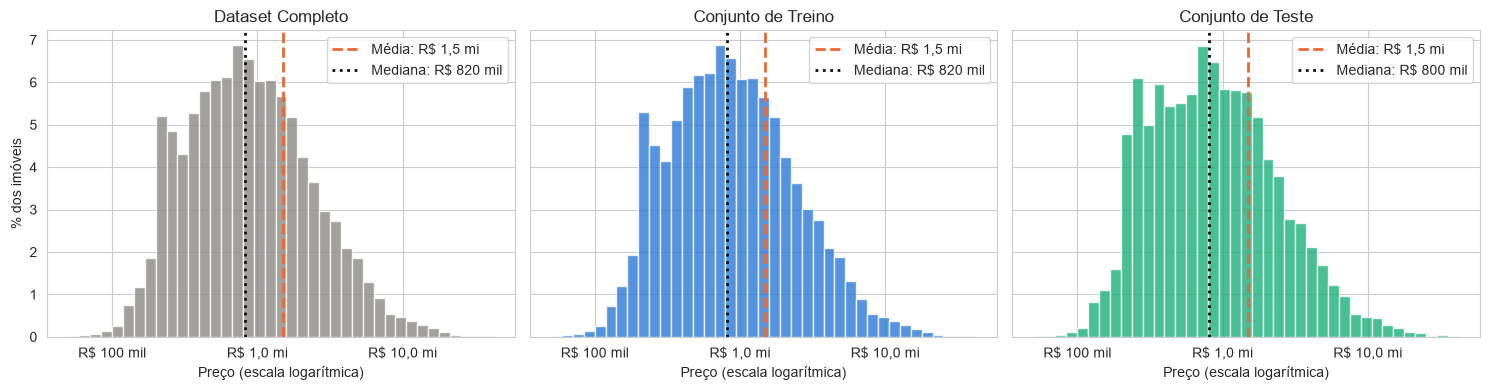


✓ Divisão concluída e verificada!
✓ O conjunto de teste está agora SELADO até o julgamento final.


In [8]:
# Visualização da distribuição da variável alvo nos três conjuntos
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
bins = np.logspace(np.log10(y.min()), np.log10(y.max()), 40)  # eixo em escala logarítmica

for ax, titulo, serie, cor in zip(axes, ["Dataset Completo", "Conjunto de Treino", "Conjunto de Teste"],
                                  [y, y_train, y_test], [CINZA, AZUL, AQUA]):
    ax.hist(serie, bins=bins, color=cor, alpha=0.8, edgecolor="white",
            weights=np.full(len(serie), 100 / len(serie)))
    ax.axvline(serie.mean(), color=LARANJA, linestyle="--", linewidth=2, label=f"Média: {reais(serie.mean())}")
    ax.axvline(serie.median(), color=TINTA, linestyle=":", linewidth=2, label=f"Mediana: {reais(serie.median())}")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(reais))
    ax.set_title(titulo)
    ax.set_xlabel("Preço (escala logarítmica)")
    ax.legend()
axes[0].set_ylabel("% dos imóveis")
plt.tight_layout()
plt.show()

print("\n✓ Divisão concluída e verificada!")
print("✓ O conjunto de teste está agora SELADO até o julgamento final.")

Os três histogramas têm o mesmo formato, e a média e a mediana caem nos mesmos lugares. O conjunto de teste é estatisticamente coerente com o treino. A partir daqui, ele fica **selado**: nenhuma célula deste notebook volta a usar `X_test` ou `y_test`.

# Capítulo 2 — O Olhar do Detetive: Análise Exploratória e Limpeza dos Dados

A regra de ouro que estende o primeiro mandamento: **o olhar do cientista se restringe ao conjunto de treino** (p. 35). Toda decisão que sair desta análise, como imputar ausentes, transformar o alvo ou tratar outliers, será tomada com informação dos 82.641 imóveis de treino.

## Passo 1: Inspeção Inicial — Conhecendo o Terreno

### Lista 2-1: Informações gerais sobre o conjunto de treino

In [9]:
# Informações gerais sobre o conjunto de treino
print("=" * 70)
print("ANÁLISE EXPLORATÓRIA DE DADOS (EDA) - CONJUNTO DE TREINO")
print("=" * 70)

print("\n1. INFORMAÇÕES GERAIS")
print("-" * 70)
print(f"Número de amostras: {br(X_train.shape[0])}")
print(f"Número de features: {X_train.shape[1]}")
print("\nTipos de dados:")
print(X_train.dtypes)

ANÁLISE EXPLORATÓRIA DE DADOS (EDA) - CONJUNTO DE TREINO

1. INFORMAÇÕES GERAIS
----------------------------------------------------------------------
Número de amostras: 82.641
Número de features: 19

Tipos de dados:
tipo                         object
subtipo                      object
bairro               string[python]
regiao                       object
fonte                        object
area_m2                     float64
quartos                     float64
banheiros                   float64
suites                      float64
vagas                       float64
condominio_iptu             float64
latitude                    float64
longitude                   float64
lancamento                    int64
tem_piscina                   int64
tem_churrasqueira             int64
tem_academia                  int64
tem_varanda                   int64
sem_itens                     int64
dtype: object


São 19 features: 5 de texto (as categóricas) e 14 numéricas, das quais 6 são binárias (0 ou 1). O `bairro` aparece como `string` porque passou por uma padronização de grafias na limpeza; para a análise, é uma categórica como as outras.

### Lista 2-1 (complemento): variáveis categóricas

O *Boston Housing* quase não tem variáveis de texto. Na base do Rio, as categóricas carregam a informação mais importante do mercado imobiliário, a localização, então merecem a mesma inspeção.

In [10]:
# Variáveis categóricas: quantas categorias e as mais frequentes
categoricas = X_train.select_dtypes(exclude="number").columns.tolist()
for col in categoricas:
    contagem = X_train[col].value_counts(dropna=False)
    print(f"\n{col}: {contagem.size} categorias")
    print((contagem.head(6) / len(X_train) * 100).round(1).to_string())

anuncios_bairro = X_train["bairro"].value_counts()
print(f"\nBairros com menos de 10 anúncios no treino: {(anuncios_bairro < 10).sum()} de {anuncios_bairro.size}"
      f" ({br(anuncios_bairro[anuncios_bairro < 10].sum())} anúncios)")


tipo: 2 categorias
tipo
apartamento    76.2
casa           23.8

subtipo: 5 categorias
subtipo
apartamento        65.8
casa               13.8
cobertura          10.0
casa_condominio    10.0
kitnet              0.4

bairro: 163 categorias
bairro
Barra da Tijuca             11.4
Recreio dos Bandeirantes    10.2
Copacabana                   8.9
Tijuca                       5.4
Botafogo                     3.9
Taquara                      2.8

regiao: 6 categorias
regiao
Barra e Jacarepaguá    38.5
Zona Sul               24.8
Zona Norte             18.0
Grande Tijuca          10.6
Zona Oeste              4.4
Centro                  3.7

fonte: 2 categorias
fonte
chavesnamao    58.7
quintoandar    41.3

Bairros com menos de 10 anúncios no treino: 18 de 163 (70 anúncios)


- **Bairro** tem 163 categorias. Barra da Tijuca (11,4%), Recreio dos Bandeirantes (10,2%) e Copacabana (8,9%) concentram 30% do treino. Os 18 bairros com menos de 10 anúncios são **categorias raras**: o modelo terá pouca evidência sobre eles, e a codificação do bairro precisará lidar com isso.
- **Região:** Barra e Jacarepaguá tem 38,5% dos anúncios e a Zona Oeste só 4,4%, apesar de ser uma das regiões mais populosas da cidade. Os portais cobrem pouco o mercado popular da Zona Oeste. É um **viés de seleção** da fonte dos dados, e o modelo deve errar mais lá.
- **Subtipo:** kitnets são só 0,4% da base.
- **Fonte:** 59% dos anúncios vêm do Chaves na Mão e 41% do QuintoAndar.

### Lista 2-2: Verificando valores ausentes

In [11]:
# Verificando valores ausentes
print("\n2. VALORES AUSENTES")
print("-" * 70)
missing_counts = X_train.isnull().sum()
missing_percentages = (missing_counts / len(X_train)) * 100

missing_df = pd.DataFrame({
    "Feature": missing_counts.index,
    "Valores Ausentes": missing_counts.values,
    "Percentual (%)": missing_percentages.values.round(2),
})

# Filtrando apenas features com valores ausentes
missing_df = missing_df[missing_df["Valores Ausentes"] > 0]

if len(missing_df) > 0:
    print(missing_df.to_string(index=False))
    print(f"\n⚠ ATENÇÃO: {len(missing_df)} feature(s) com valores ausentes detectada(s)!")
else:
    print("✓ Nenhum valor ausente detectado no conjunto de treino.")


2. VALORES AUSENTES
----------------------------------------------------------------------
        Feature  Valores Ausentes  Percentual (%)
        quartos               490            0.59
      banheiros               819            0.99
          vagas                 1            0.00
condominio_iptu              9595           11.61
       latitude             20163           24.40
      longitude             20163           24.40

⚠ ATENÇÃO: 6 feature(s) com valores ausentes detectada(s)!


Diferente do Boston, que não tem nenhum ausente (p. 38), a base do Rio tem seis features com lacunas. Antes de escolher entre as três estratégias do livro (remoção, imputação ou codificação), é preciso entender **de onde** vem cada ausência.

### Lista 2-2 (complemento): a origem dos ausentes e os ausentes disfarçados

In [12]:
# De onde vêm os ausentes: percentual ausente por portal e por tipo de imóvel
com_ausentes = missing_df["Feature"].tolist()
print("Ausentes por portal (%):")
print((X_train[com_ausentes].isnull().groupby(X_train["fonte"]).mean() * 100).round(1).T.to_string())
print("\nCondomínio + IPTU ausente por subtipo (%):")
print((X_train["condominio_iptu"].isnull().groupby(X_train["subtipo"]).mean() * 100).round(1).to_string())

# Ausentes disfarçados: zeros que podem significar "não informado"
print("\nAusentes disfarçados (%):")
disfarcados = pd.DataFrame({
    "suites = 0": X_train["suites"].eq(0),
    "vagas = 0": X_train["vagas"].eq(0),
    "sem lista de itens": X_train["sem_itens"].eq(1),
}).groupby(X_train["fonte"]).mean() * 100
print(disfarcados.round(1).T.to_string())

Ausentes por portal (%):
fonte            chavesnamao  quintoandar
quartos                  1.0          0.0
banheiros                1.6          0.1
vagas                    0.0          0.0
condominio_iptu         12.2         10.8
latitude                 3.6         54.0
longitude                3.6         54.0

Condomínio + IPTU ausente por subtipo (%):
subtipo
apartamento         9.7
casa               27.6
casa_condominio     7.8
cobertura           6.3
kitnet              8.5

Ausentes disfarçados (%):
fonte               chavesnamao  quintoandar
suites = 0                 35.4         36.5
vagas = 0                  20.3         19.5
sem lista de itens         16.0          7.4


- **Coordenadas (24%)** são uma ausência **estrutural**. O QuintoAndar não informa latitude e longitude; 54% dos seus imóveis continuam sem coordenada, e os demais a herdaram do anúncio do mesmo imóvel no Chaves na Mão. No Chaves na Mão faltam só 3,6%, contando as que a limpeza anulou. Remover essas linhas apagaria mais da metade do QuintoAndar, então a posição desses imóveis terá de vir do bairro, com a posição média calculada no treino.
- **Condomínio + IPTU (12%):** a ausência é quase o triplo nas casas de rua (27,6%) do que nos apartamentos (9,7%), porque muitas casas não têm condomínio. Aqui a ausência **tem significado**, e um marcador explícito de ausência (a estratégia de codificação) preserva essa informação.
- **Quartos e banheiros (cerca de 1%):** ausências pontuais, quase todas do Chaves na Mão. A imputação resolve.

**Ausentes disfarçados** (p. 38) são zeros que podem significar "não informado". O Chaves na Mão omite suítes e vagas quando são zero, e a limpeza preencheu essas omissões com 0. A proporção de zeros é praticamente igual nos dois portais (cerca de 36% sem suíte e 20% sem vaga), o que indica que são zeros reais. Já as comodidades valem 0 também quando o anúncio não traz lista de itens, o que acontece em 16,0% do Chaves na Mão e 7,4% do QuintoAndar. Por isso existe a flag `sem_itens`: ela diz ao modelo quando o 0 significa "não informado".

A estratégia final será decidida no pipeline, com estatísticas calculadas só no treino.

## Passo 2: Estatísticas Descritivas — O Perfil dos Dados

### Lista 2-3: Estatísticas descritivas da base de treino

In [13]:
# Estatísticas descritivas da base de treino
print("\n3. ESTATÍSTICAS DESCRITIVAS")
print("-" * 70)
desc_stats = X_train.describe().T
desc_stats["range"] = desc_stats["max"] - desc_stats["min"]
print(desc_stats[["mean", "std", "min", "max", "range"]].round(3).to_string())
print(f"\nLançamentos no treino: {X_train['lancamento'].sum()} de {br(len(X_train))}")


3. ESTATÍSTICAS DESCRITIVAS
----------------------------------------------------------------------
                       mean       std     min        max      range
area_m2             161.261   163.231  15.000   4930.000   4915.000
quartos               2.851     1.139   0.000     10.000     10.000
banheiros             2.738     1.679   1.000     12.000     11.000
suites                1.114     1.225   0.000     10.000     10.000
vagas                 1.474     1.311   0.000     10.000     10.000
condominio_iptu    1888.155  2440.854   1.000  72355.000  72354.000
latitude            -22.943     0.052 -23.072    -22.747      0.325
longitude           -43.304     0.108 -43.764    -43.094      0.670
lancamento            0.000     0.009   0.000      1.000      1.000
tem_piscina           0.366     0.482   0.000      1.000      1.000
tem_churrasqueira     0.384     0.486   0.000      1.000      1.000
tem_academia          0.248     0.432   0.000      1.000      1.000
tem_varanda     

As escalas são muito heterogêneas, como no Boston (p. 40):

- a área vai de 15 a 4.930 m²;
- o condomínio + IPTU vai de R\$ 1 a R\$ 72.355 por mês;
- a latitude e a longitude variam menos de um grau;
- as binárias ficam entre 0 e 1.

Modelos lineares e baseados em distância seriam dominados pelas variáveis de escala maior, então será necessária a **padronização** (`StandardScaler`) antes deles.

Nas binárias, a média é a proporção de anúncios com o item: 36,6% listam piscina e 41,4% listam varanda. A `lancamento` é praticamente constante: só 7 dos 82.641 anúncios de treino são lançamentos. É candidata natural ao filtro de baixa variância do capítulo 3. O condomínio mínimo de R\$ 1 por mês só pode ser um preenchimento simbólico do anunciante.

## Passo 3: Detecção de Outliers — Os Valores Extremos

### Lista 2-4: Detecção de Outliers

Usamos o método do **Intervalo Interquartil (IQR)** do livro: é outlier o valor abaixo de Q1 − 1,5×IQR ou acima de Q3 + 1,5×IQR. Uma adaptação: as variáveis binárias ficam de fora. No Boston, o livro aplicou o IQR à `chas` (0 ou 1) e marcou 29 "outliers", que são só os imóveis com valor 1. Numa variável binária, o IQR não mede nada.

In [14]:
# Detecção de Outliers
print("\n4. DETECÇÃO DE OUTLIERS (Método IQR)")
print("-" * 70)

def detect_outliers_iqr(data, feature):
    """
    Detecta outliers usando o método do Intervalo Interquartil (IQR).
    Outliers são definidos como valores abaixo de Q1 - 1.5*IQR ou acima de Q3 + 1.5*IQR.
    """
    Q1 = data[feature].quantile(0.25)
    Q3 = data[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]
    return len(outliers), lower_bound, upper_bound

# O IQR só faz sentido em variáveis com escala: as binárias (0/1) ficam de fora
numericas = X_train.select_dtypes("number").columns
binarias = [c for c in numericas if set(X_train[c].dropna().unique()) <= {0, 1}]
numericas = [c for c in numericas if c not in binarias]

outlier_summary = []
for feature in numericas:
    n_outliers, lower, upper = detect_outliers_iqr(X_train, feature)
    outlier_percentage = (n_outliers / len(X_train)) * 100
    outlier_summary.append({
        "Feature": feature,
        "N° Outliers": n_outliers,
        "Percentual (%)": f"{outlier_percentage:.2f}%",
        "Limite Inferior": f"{lower:.2f}",
        "Limite Superior": f"{upper:.2f}",
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df = outlier_df[outlier_df["N° Outliers"] > 0].sort_values("N° Outliers", ascending=False)

print(outlier_df.to_string(index=False))
print(f"\n📊 Total de features com outliers: {len(outlier_df)} de {len(numericas)} numéricas"
      f" (as {len(binarias)} binárias ficaram de fora)")


4. DETECÇÃO DE OUTLIERS (Método IQR)
----------------------------------------------------------------------


        Feature  N° Outliers Percentual (%) Limite Inferior Limite Superior
      banheiros        11168         13.51%            0.50            4.50
         suites        11159         13.50%           -1.50            2.50
        area_m2         5985          7.24%         -116.00          380.00
          vagas         5942          7.19%           -0.50            3.50
        quartos         5680          6.87%            0.50            4.50
condominio_iptu         4750          5.75%        -1880.00         4800.00
       latitude          602          0.73%          -23.09          -22.80
      longitude          183          0.22%          -43.63          -42.94

📊 Total de features com outliers: 8 de 8 numéricas (as 6 binárias ficaram de fora)


Todas as 8 features numéricas têm outliers:

| Feature | Outliers | Além do limite |
|---|---|---|
| banheiros | 13,5% | acima de 4,5 |
| suítes | 13,5% | acima de 2,5 |
| área | 7,2% | acima de 380 m² |
| vagas | 7,2% | acima de 3,5 |
| quartos | 6,9% | acima de 4,5 ou 0 quartos (95 anúncios, quase todos apartamentos e casas: provável falta de informação) |
| condomínio + IPTU | 5,7% | acima de R\$ 4.800 |
| latitude | 0,7% | ao norte de −22,80 |
| longitude | 0,2% | a oeste de −43,63 |

As taxas das contagens, da área e do condomínio ficam na faixa de 5% a 15% que o livro considera comum em dados reais (p. 42); as das coordenadas ficam abaixo de 1%. Os limites inferiores negativos, como −116 m², mostram uma limitação do IQR: ele supõe uma distribuição simétrica, e aqui só a cauda de cima importa.

### Lista 2-4 (complemento): visualizando os outliers

O quadro ATENÇÃO do livro (p. 42) recomenda visualizar os outliers antes de decidir qualquer coisa. A área e o condomínio usam escala logarítmica, porque se espalham por três ordens de grandeza.

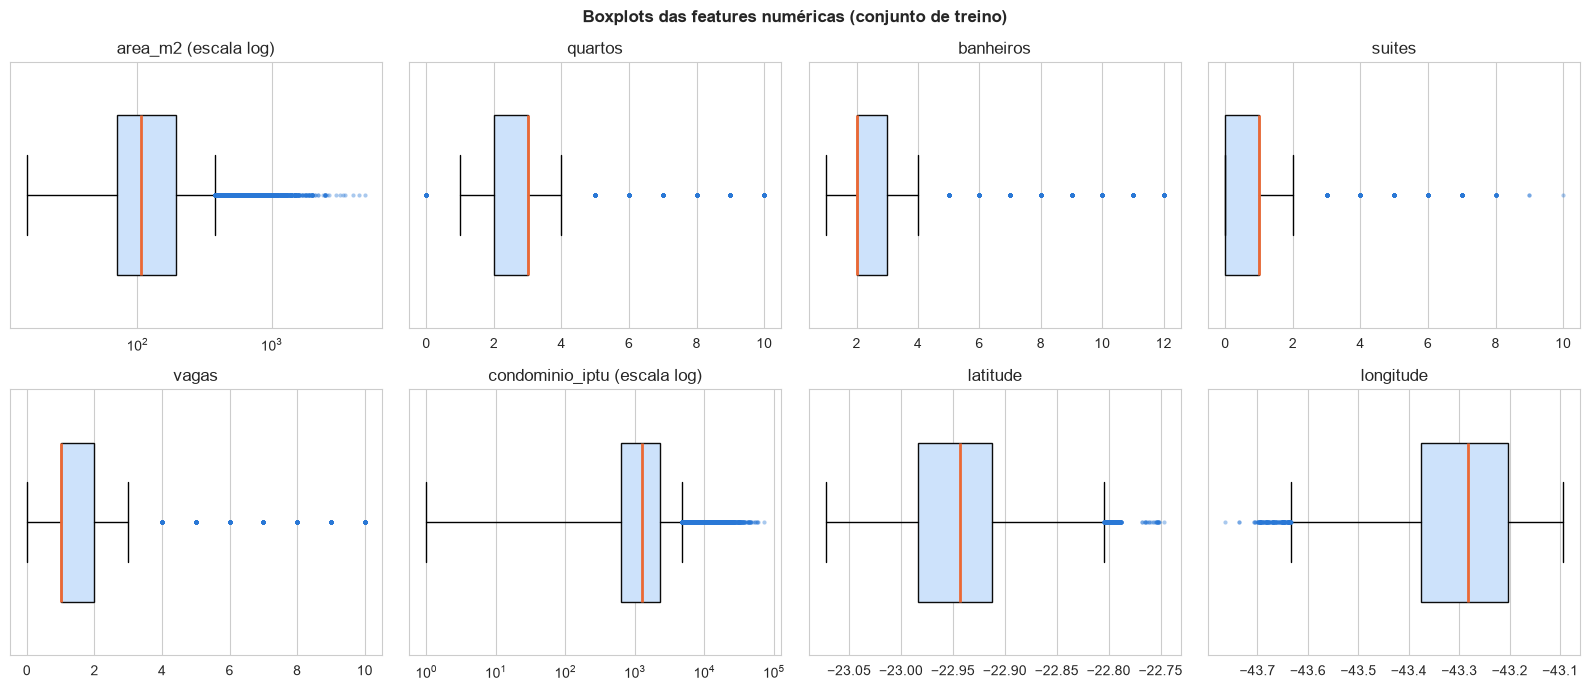

In [15]:
# Visualizando os outliers com boxplots
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, feature in zip(axes.flat, numericas):
    valores = X_train[feature].dropna()
    ax.boxplot(valores, vert=False, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", color=TINTA), medianprops=dict(color=LARANJA, linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.4))
    if feature in ("area_m2", "condominio_iptu"):
        ax.set_xscale("log")
        ax.set_title(f"{feature} (escala log)")
    else:
        ax.set_title(feature)
    ax.set_yticks([])
plt.suptitle("Boxplots das features numéricas (conjunto de treino)", fontweight="bold")
plt.tight_layout()
plt.show()

Nas contagens (quartos, banheiros, suítes, vagas), os outliers são valores inteiros altos, como 6 suítes ou 10 banheiros, típicos de casas grandes. Na área e no condomínio, a cauda de cima é longa e contínua, e não há um salto que separe um grupo de erros.

### Lista 2-4 (complemento): os casos mais extremos

Distinguir o erro do extraordinário exige intuição de domínio (p. 41). Olhamos os casos mais extremos, com o preço, que pertence ao treino, e os outliers de coordenadas.

In [16]:
# Os casos mais extremos: erro de digitação ou imóvel raro?
mostrar = ["tipo", "subtipo", "bairro", "area_m2", "quartos", "suites", "vagas", "condominio_iptu"]
treino = X_train.assign(preco=y_train)
for feature in ["area_m2", "condominio_iptu", "vagas"]:
    print(f"\nMaiores valores de {feature}:")
    print(treino.nlargest(5, feature)[mostrar + ["preco"]].to_string())

# Coordenadas: bairro na borda da cidade ou coordenada que não bate com o bairro?
for feature in ["latitude", "longitude"]:
    _, lower, upper = detect_outliers_iqr(X_train, feature)
    fora = X_train[(X_train[feature] < lower) | (X_train[feature] > upper)]
    print(f"\nOutliers de {feature} por bairro ({len(fora)} anúncios):")
    print(fora["bairro"].value_counts().head(8).to_string())

mediana_bairro = X_train.groupby("bairro")[["latitude", "longitude"]].transform("median")
distancia_km = np.hypot((X_train["latitude"] - mediana_bairro["latitude"]) * 111,
                        (X_train["longitude"] - mediana_bairro["longitude"]) * 102)
for km in [5, 10]:
    longe = distancia_km > km
    print(f"\nCoordenadas a mais de {km} km da posição mediana do próprio bairro: {br(longe.sum())}"
          f" de {br(X_train['latitude'].notna().sum())} com coordenada. Bairros mais frequentes:")
    print(X_train.loc[longe, "bairro"].value_counts().head(6).to_string())


Maiores valores de area_m2:
               tipo      subtipo                bairro  area_m2  quartos  suites  vagas  condominio_iptu       preco
42038   apartamento  apartamento                 Gávea   4930.0      6.0     1.0    4.0       460.000000   7500000.0
42587   apartamento  apartamento       Barra da Tijuca   4500.0      4.0     0.0    4.0              NaN  13000000.0
102487         casa         casa                   Joá   4000.0      4.0     4.0    7.0      4666.666667  38000000.0
103133         casa         casa  São Francisco Xavier   3509.0      4.0     0.0    2.0      8557.000000   5000000.0
103077         casa         casa           São Conrado   3420.0      5.0     5.0    4.0      9416.000000  35000000.0

Maiores valores de condominio_iptu:
              tipo          subtipo           bairro  area_m2  quartos  suites  vagas  condominio_iptu       preco
42513         casa             casa  Barra da Tijuca   1670.0      4.0     4.0    6.0          72355.0   9787000.0
42

- **Imóveis raros e legítimos:** as casas de 4.000 m² no Joá (R\$ 38 mi) e de 3.420 m² em São Conrado (R\$ 35 mi) são mansões. Os condomínios acima de R\$ 50 mil são de coberturas, casas e apartamentos de luxo no Leblon e na Barra.
- **Prováveis erros:** os "apartamentos" de 4.930 m² na Gávea (R\$ 7,5 mi, condomínio de R\$ 460) e de 4.500 m² na Barra (R\$ 13 mi, sem condomínio) provavelmente informam a área do terreno. O apartamento de 300 m² no Méier com 10 vagas e condomínio de R\$ 2 por R\$ 380 mil é um erro de digitação.
- **Coordenadas na borda:** entre os bairros mais frequentes, os outliers de latitude são todos da Ilha do Governador e de Paquetá (Freguesia, Portuguesa, Tauá, Bancários, Jardim Carioca, Moneró, Cocotá), ao norte. Os de longitude são quase todos do extremo oeste (Santa Cruz, Guaratiba, Paciência, Sepetiba). Aqui o IQR marca a geografia legítima da cidade. As exceções visíveis, como 7 anúncios do Maracanã e 5 do Recreio a oeste, são coordenadas erradas.
- **Coordenadas longe do bairro:** o IQR não pega coordenadas erradas que caem dentro da cidade. A distância até a posição mediana do próprio bairro mostra 2.653 coordenadas a mais de 5 km. A maioria é da Barra da Tijuca, de Jacarepaguá, do Recreio e de Campo Grande, bairros extensos e, no caso da Barra, usados nos anúncios também para a vizinhança. Já as 397 coordenadas a mais de 10 km incluem casos que só podem ser erro de geocodificação do anunciante, como 22 anúncios da Tijuca e 13 de Vista Alegre, bairros compactos.

Seguimos a cautela do livro (p. 42): **os outliers são mantidos**, a menos que haja prova irrefutável de que são falsos. Os erros evidentes ficam registrados para o pipeline. A posição do imóvel, por exemplo, pode vir do bairro quando a coordenada estiver longe demais dele.

### Lista 2-5: "score de outlier" para cada amostra

Como no livro, cada amostra ganha um ponto por feature fora dos limites do IQR, e as amostras com **6 ou mais** outliers são as "extremas" que serão monitoradas.

In [17]:
# "score de outlier" para cada amostra
# Conta quantas features de cada amostra são outliers
outlier_scores = pd.Series(0, index=X_train.index)

for feature in numericas:
    _, lower, upper = detect_outliers_iqr(X_train, feature)
    is_outlier = (X_train[feature] < lower) | (X_train[feature] > upper)
    outlier_scores += is_outlier.astype(int)

print("\n5. SCORE DE OUTLIER POR AMOSTRA")
print("-" * 70)
print(f"Amostras com 0 outliers: {br((outlier_scores == 0).sum())}")
print(f"Amostras com 1-2 outliers: {br(((outlier_scores >= 1) & (outlier_scores <= 2)).sum())}")
print(f"Amostras com 3-5 outliers: {br(((outlier_scores >= 3) & (outlier_scores <= 5)).sum())}")
print(f"Amostras com 6+ outliers: {br((outlier_scores >= 6).sum())}")

# Identificando as amostras mais "extremas"
extreme_samples = outlier_scores[outlier_scores >= 6].sort_values(ascending=False)
if len(extreme_samples) > 0:
    print(f"\n⚠ {br(len(extreme_samples))} amostras com 6 ou mais features outliers detectadas.")
    print("  Essas amostras serão monitoradas durante a modelagem.")
    print("\nPerfil das amostras com 6 ou mais outliers (%):")
    print((X_train.loc[extreme_samples.index, ["tipo", "regiao"]].value_counts(normalize=True).head(6) * 100).round(1).to_string())
    print("\nMediana das amostras com 6 ou mais outliers x todas do treino:")
    print(pd.DataFrame({"6+ outliers": X_train.loc[extreme_samples.index, numericas[:6]].median(),
                        "treino": X_train[numericas[:6]].median()}).round(0).to_string())


5. SCORE DE OUTLIER POR AMOSTRA
----------------------------------------------------------------------
Amostras com 0 outliers: 61.245
Amostras com 1-2 outliers: 14.791
Amostras com 3-5 outliers: 6.204
Amostras com 6+ outliers: 401

⚠ 401 amostras com 6 ou mais features outliers detectadas.
  Essas amostras serão monitoradas durante a modelagem.

Perfil das amostras com 6 ou mais outliers (%):
tipo         regiao             
casa         Barra e Jacarepaguá    68.1
apartamento  Barra e Jacarepaguá    20.2
             Zona Sul                5.0
casa         Zona Sul                4.2
             Zona Norte              1.5
             Zona Oeste              0.5

Mediana das amostras com 6 ou mais outliers x todas do treino:
                 6+ outliers  treino
area_m2                800.0   107.0
quartos                  5.0     3.0
banheiros                7.0     2.0
suites                   5.0     1.0
vagas                    5.0     1.0
condominio_iptu       6933.0  1280.0


| Outliers por amostra | Imóveis | % do treino |
|---|---|---|
| 0 | 61.245 | 74,1% |
| 1 a 2 | 14.791 | 17,9% |
| 3 a 5 | 6.204 | 7,5% |
| 6 ou mais | 401 | 0,5% |

No Boston, nenhuma amostra chegou a 6 outliers (p. 44). Aqui, 401 chegam. O perfil explica: 68,1% delas são casas na região de Barra e Jacarepaguá. A mediana dessas amostras tem 800 m², 7 banheiros, 5 suítes, 5 vagas e R\$ 6.933 de condomínio + IPTU, contra 107 m², 2 banheiros, 1 suíte, 1 vaga e R\$ 1.280 no treino todo. São o topo do mercado, não erros. O `outlier_scores` fica guardado: quando o modelo errar, saberemos se o erro se concentra nessas amostras.

## Passo 4: Análise da Variável Alvo — O Coração do Problema

### Lista 2-6: Análise da variável alvo

In [18]:
print("\n6. ANÁLISE DA VARIÁVEL ALVO (y_train)")
print("-" * 70)

# Estatísticas descritivas da variável alvo
print(f"Média:    R$ {br(y_train.mean() / 1e3, 1)} mil")
print(f"Mediana:  R$ {br(y_train.median() / 1e3, 1)} mil")
print(f"Desvio:   R$ {br(y_train.std() / 1e3, 1)} mil")
print(f"Mínimo:   R$ {br(y_train.min() / 1e3, 1)} mil")
print(f"Máximo:   R$ {br(y_train.max() / 1e3, 1)} mil")
print(f"Assimetria (Skewness): {y_train.skew():.3f}")
print(f"Curtose (Kurtosis):    {y_train.kurtosis():.3f}")

# Interpretação da assimetria
skewness = y_train.skew()
if abs(skewness) < 0.5:
    skew_interpretation = "aproximadamente simétrica"
elif skewness > 0:
    skew_interpretation = "assimétrica à direita (cauda longa à direita)"
else:
    skew_interpretation = "assimétrica à esquerda (cauda longa à esquerda)"

print(f"\n📊 Interpretação: A distribuição é {skew_interpretation}.")


6. ANÁLISE DA VARIÁVEL ALVO (y_train)
----------------------------------------------------------------------
Média:    R$ 1.488,9 mil
Mediana:  R$ 820,0 mil
Desvio:   R$ 2.116,4 mil
Mínimo:   R$ 50,0 mil
Máximo:   R$ 42.257,9 mil
Assimetria (Skewness): 5.177
Curtose (Kurtosis):    45.891

📊 Interpretação: A distribuição é assimétrica à direita (cauda longa à direita).


O retrato do alvo:

- A **média de R\$ 1,49 mi fica 82% acima da mediana de R\$ 820 mil**. Poucos imóveis muito caros puxam a média para cima.
- A **assimetria de 5,18** é cerca de cinco vezes a do Boston (1,049), e a **curtose de 45,9** é cerca de 37 vezes maior (1,242). A cauda é muito mais pesada.
- O mínimo de R\$ 50 mil é o limite da limpeza, e o máximo é de R\$ 42,3 mi.

Sem tratamento, um modelo linear tenderia a **subestimar os imóveis mais caros** (p. 47), o mesmo erro estrutural do Apolo (p. 49).

### Lista 2-7: Analisando visualmente a variável alvo

O mesmo painel do livro: histograma com densidade, boxplot, Q-Q plot e valores ordenados. Só o histograma corta o eixo no percentil 99, para que a parte central fique visível; os outros três gráficos mostram todos os imóveis.

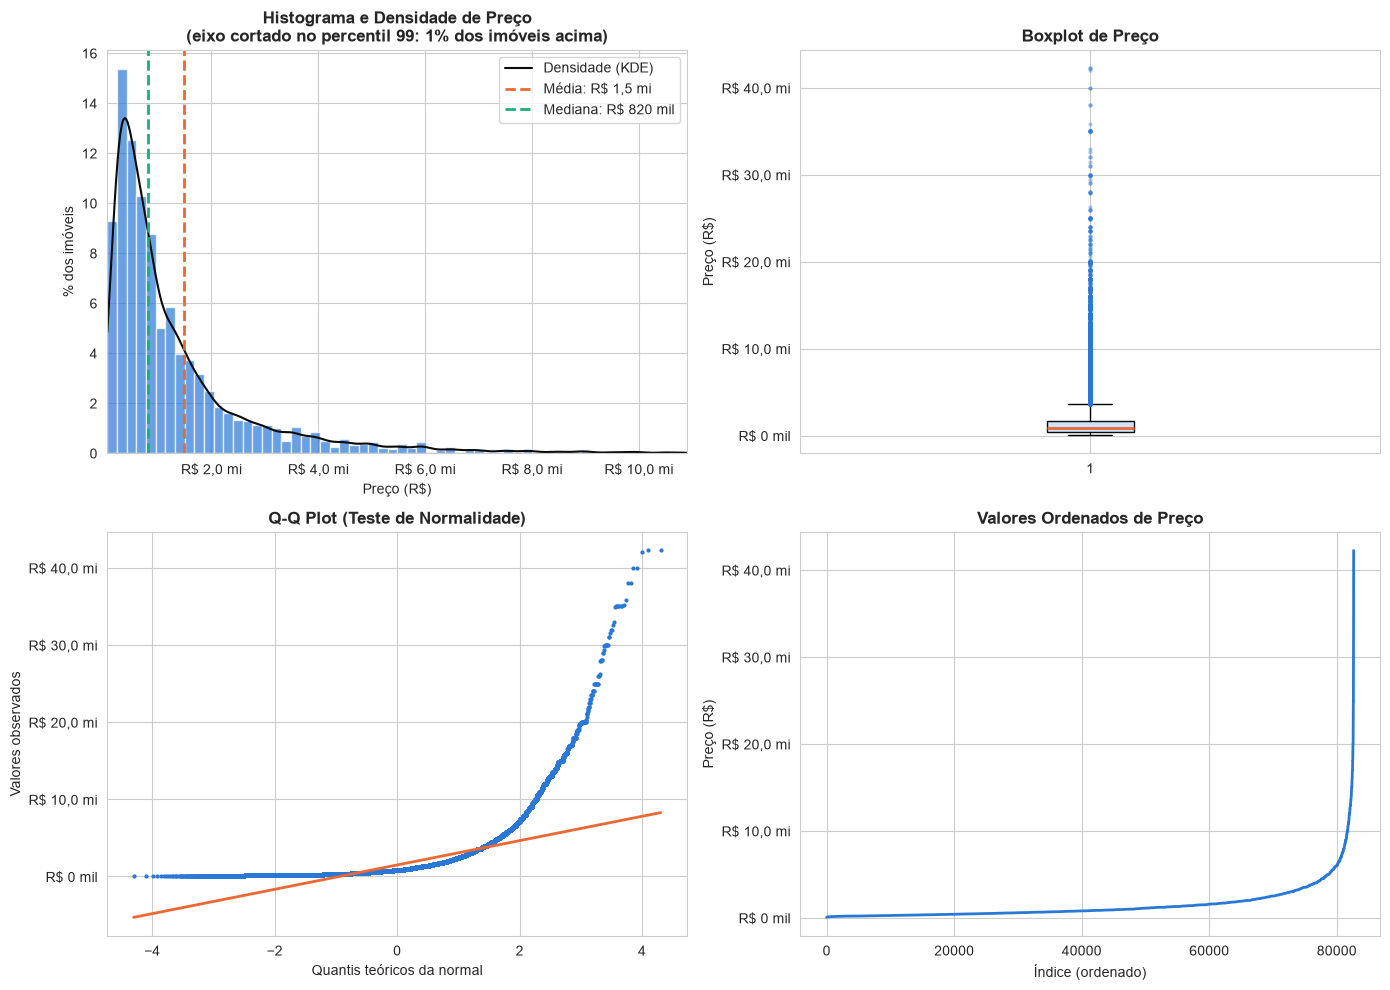

In [19]:
# Criando uma figura com múltiplos subplots para análise da variável alvo
def painel_alvo(serie, titulo, rotulo, formato, corte=None):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    visivel = serie if corte is None else serie[serie <= corte]

    # 1. Histograma com curva KDE (a curva na mesma escala: % dos imóveis por faixa)
    ax = axes[0, 0]
    _, bordas, _ = ax.hist(visivel, bins=60, color=AZUL, alpha=0.7, edgecolor="white",
                           weights=np.full(len(visivel), 100 / len(serie)))
    xs = np.linspace(bordas[0], bordas[-1], 400)
    escala = (bordas[1] - bordas[0]) * 100 * len(visivel) / len(serie)
    ax.plot(xs, stats.gaussian_kde(visivel)(xs) * escala, color=TINTA, linewidth=1.5, label="Densidade (KDE)")
    ax.axvline(serie.mean(), color=LARANJA, linestyle="--", linewidth=2, label=f"Média: {formato(serie.mean())}")
    ax.axvline(serie.median(), color=AQUA, linestyle="--", linewidth=2, label=f"Mediana: {formato(serie.median())}")
    ax.set_xlim(visivel.min(), visivel.max())
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(formato))
    nota = "" if corte is None else f"\n(eixo cortado no percentil 99: {(serie > corte).mean():.0%} dos imóveis acima)"
    ax.set_title(f"Histograma e Densidade de {titulo}{nota}", fontsize=12, fontweight="bold")
    ax.set_xlabel(rotulo)
    ax.set_ylabel("% dos imóveis")
    ax.legend()

    # 2. Boxplot
    ax = axes[0, 1]
    ax.boxplot(serie, vert=True, patch_artist=True, boxprops=dict(facecolor="#cde2fb", color=TINTA),
               medianprops=dict(color=LARANJA, linewidth=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=AZUL, markeredgecolor="none", alpha=0.4))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato))
    ax.set_title(f"Boxplot de {titulo}", fontsize=12, fontweight="bold")
    ax.set_ylabel(rotulo)

    # 3. Q-Q Plot (Quantile-Quantile)
    ax = axes[1, 0]
    stats.probplot(serie, dist="norm", plot=ax)
    ax.get_lines()[0].set(marker="o", markersize=2, markerfacecolor=AZUL, markeredgecolor=AZUL)
    ax.get_lines()[1].set(color=LARANJA, linewidth=2)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato))
    ax.set_title("Q-Q Plot (Teste de Normalidade)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Quantis teóricos da normal")
    ax.set_ylabel("Valores observados")

    # 4. Gráfico de dispersão dos valores ordenados
    ax = axes[1, 1]
    ax.plot(np.sort(serie.to_numpy()), color=AZUL, linewidth=2)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(formato))
    ax.set_title(f"Valores Ordenados de {titulo}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Índice (ordenado)")
    ax.set_ylabel(rotulo)

    plt.tight_layout()
    plt.show()

painel_alvo(y_train, "Preço", "Preço (R$)", reais, corte=y_train.quantile(0.99))

- **Histograma:** a maior parte dos imóveis fica abaixo de R\$ 2 mi, com uma cauda longa à direita (assimetria positiva).
- **Boxplot:** os pontos acima do bigode superior são milhares de imóveis caros. São exceções legítimas do mercado, não erros (p. 49).
- **Q-Q plot:** a curva se afasta da reta da normal com força na direita, confirmando a cauda pesada.
- **Valores ordenados:** a subida é suave até os últimos 5% e explode no final, a descontinuidade que desafia os modelos lineares.

### Lista 2-7 (complemento): o efeito da transformação logarítmica

O livro decide aplicar `log1p(y)` ao alvo, com o `TransformedTargetRegressor`, que treina na escala transformada e devolve as previsões em reais com `expm1` (p. 49). Aqui só antecipamos o efeito da transformação no treino; ela será aplicada de fato no pipeline.

Assimetria (Skewness) de log1p(preço): 0.343   (antes: 5.177)
Curtose (Kurtosis) de log1p(preço):    -0.217   (antes: 45.891)


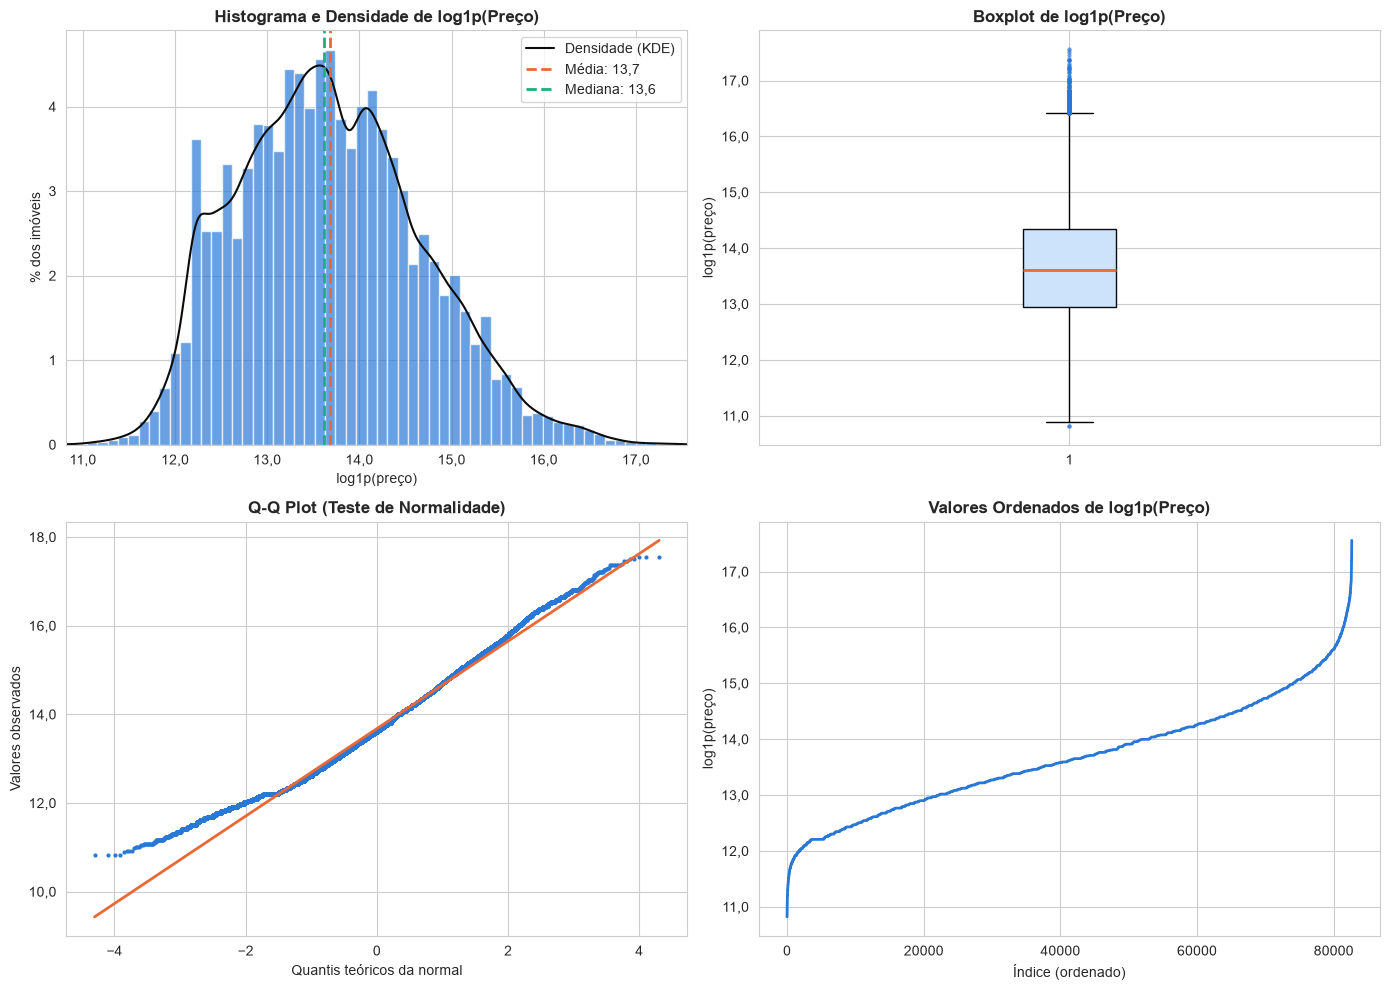

In [20]:
# A mesma análise depois da transformação logarítmica log1p(y) = log(1 + y)
y_log = np.log1p(y_train)
print(f"Assimetria (Skewness) de log1p(preço): {y_log.skew():.3f}   (antes: {y_train.skew():.3f})")
print(f"Curtose (Kurtosis) de log1p(preço):    {y_log.kurtosis():.3f}   (antes: {y_train.kurtosis():.3f})")

painel_alvo(y_log, "log1p(Preço)", "log1p(preço)", lambda v, _=None: br(v, 1))

A transformação faz o que o livro promete:

- a **assimetria cai de 5,18 para 0,34** e a **curtose de 45,9 para −0,22**;
- o Q-Q plot fica quase sobre a reta da normal, com pequenos desvios só nas pontas;
- o boxplot fica simétrico, e os pontos isolados de cima são bem menos numerosos.

Os picos no histograma são preços redondos, que os anunciantes preferem: R\$ 200 mil, o preço mais comum do treino (1.760 anúncios), R\$ 300 mil e R\$ 400 mil. A transformação também deixa os erros mais comparáveis. Errar R\$ 100 mil num imóvel de R\$ 300 mil é grave, mas num de R\$ 10 mi é pouco, e na escala logarítmica o erro passa a ser medido em proporção do preço.

### Lista 2-8: Análise Exploratória de Dados (EDA) concluída

In [21]:
# Análise Exploratória de Dados (EDA) concluída
pct_coord = X_train["latitude"].isnull().mean() * 100
pct_cond = X_train["condominio_iptu"].isnull().mean() * 100
print("\n✓ Análise Exploratória de Dados (EDA) concluída!")
print("✓ Principais descobertas registradas:")
print(f"  - Valores ausentes: coordenadas ({pct_coord:.0f}%, quase todas do QuintoAndar) e"
      f" condomínio + IPTU ({pct_cond:.0f}%) → imputação no pipeline")
print(f"  - Outliers presentes em {len(outlier_df)} features, mas mantidos (parte legítima da distribuição)"
      f" e marcados no score de outlier")
print("  - Escalas das features são heterogêneas → Necessária padronização")
print(f"  - lancamento é quase constante ({X_train['lancamento'].sum()} anúncios) → candidata ao filtro de baixa variância")
print(f"  - Variável alvo tem assimetria positiva forte ({y_train.skew():.1f}) → Necessária transformação log")
print(f"  - Bairro tem {X_train['bairro'].nunique()} categorias, {(anuncios_bairro < 10).sum()} delas com menos"
      f" de 10 anúncios → codificação que lide com categorias raras")
print("\n➡ Próximo passo: Transformação e Engenharia de Features")


✓ Análise Exploratória de Dados (EDA) concluída!
✓ Principais descobertas registradas:
  - Valores ausentes: coordenadas (24%, quase todas do QuintoAndar) e condomínio + IPTU (12%) → imputação no pipeline
  - Outliers presentes em 8 features, mas mantidos (parte legítima da distribuição) e marcados no score de outlier
  - Escalas das features são heterogêneas → Necessária padronização
  - lancamento é quase constante (7 anúncios) → candidata ao filtro de baixa variância
  - Variável alvo tem assimetria positiva forte (5.2) → Necessária transformação log
  - Bairro tem 163 categorias, 18 delas com menos de 10 anúncios → codificação que lide com categorias raras

➡ Próximo passo: Transformação e Engenharia de Features


## Conclusões dos capítulos 1 e 2

| Descoberta | Consequência para os próximos capítulos |
|---|---|
| A base tinha 34,8% de anúncios repetidos, e sobram quase duplicatas | Divisão agrupada por imóvel; o teste fica selado, com impressão digital para conferência |
| Coordenadas ausentes em 24% (54% do QuintoAndar); condomínio + IPTU em 12%, e 28% nas casas de rua | Imputação com estatísticas do treino e marcador de ausência; posição pelo bairro |
| Coordenadas longe do próprio bairro, algumas por erro de geocodificação | Usar a posição do bairro quando a coordenada estiver longe demais |
| Comodidades valem 0 quando o anúncio não lista itens | Manter a flag `sem_itens` |
| Escalas muito diferentes entre as features | Padronização para os modelos lineares |
| Outliers em todas as numéricas, quase todos legítimos (o topo do mercado) | Mantidos e marcados pelo score de outlier; poucos erros evidentes |
| Alvo com assimetria 5,2 e curtose 45,9 | `log1p` no alvo com `TransformedTargetRegressor` |
| `bairro` com 163 categorias, 18 delas raras | Codificação que lide com categorias raras (capítulo 3) |
| `lancamento` praticamente constante | Candidata ao filtro de baixa variância (capítulo 3) |
| Zona Oeste com só 4,4% dos anúncios | Viés de seleção dos portais; esperar erro maior nessa região |

O conjunto de teste continua selado: nenhuma célula do capítulo 2 usou `X_test` ou `y_test`. O próximo passo é o capítulo 3, *A Arte da Alquimia: Feature Engineering e Seleção*.